# Poda por cosseno no GraphPFN com a camada 0 protegida: removendo as *k* camadas de menor BI (exceto a 0)

Este notebook aplica a **poda por cosseno** (Block Influence, ShortGPT) ao GraphPFN e compara cada modelo podado com o **modelo inteiro** (12 camadas).

$$BI_{\cos}(l) = 1 - \cos(h_l^{in}, h_l^{out})$$

Uma camada com BI baixo quase não altera sua entrada (age como identidade). A poda remove as camadas em ordem crescente de BI:

| Configuração | Camadas removidas |
|---|---|
| Inteiro | nenhuma (12 camadas) |
| k = 2 | as 2 camadas de menor BI entre as camadas 1–11 |
| k = 3 | as 3 camadas de menor BI entre as camadas 1–11 |
| … | … |
| k = 11 | as camadas 1–11 (sobra só a camada 0) |

**Protocolo.** Mesmo pipeline do notebook `analise_camadas_e_poda_graphpfn.ipynb`: pré-processamento oficial (`predict_icl`), split oficial, 3 sementes pareadas, sem re-treino. O BI é medido sobre **todos os tokens** com o modelo inteiro, e o ranking é calculado **por dataset**.

**Diferença para `poda_cosseno_k_menores_graphpfn.ipynb`:** a camada 0 **nunca é removida**. Na versão sem restrição, o modelo colapsava assim que a camada 0 entrava na lista de poda (k = 4 ou 5). A camada 0 tem BI baixo na média de todos os tokens, mas é a que mais transforma o token-alvo. A Seção 3.4 compara as duas versões.

**Métricas reportadas (teste):**

| Tarefa | Métricas | Melhor |
|---|---|---|
| Classificação binária (tolokers-2) | ROC-AUC, Average Precision | ↑ |
| Multiclasse (cora, pubmed) | Acurácia, F1-macro | ↑ |
| Regressão (city-roads-M, artnet-views) | R², MAE, RMSE | R² ↑, MAE/RMSE ↓ |

Cada configuração mostra o **valor da métrica** (média ± desvio-padrão em 3 sementes) e a **diferença (Δ) em relação ao modelo inteiro**, na mesma unidade da métrica.

## 0. Configuração

In [1]:
import os, sys, time, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from contextlib import contextmanager

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src" / "graphpfn").exists() else cwd / "GraphFPN"
os.chdir(PROJECT_ROOT)  # LimiXWrapper procura ./checkpoints/LimiX-16M.ckpt
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import dgl
import dgl.data
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, mean_squared_error
from IPython.display import display

from graphpfn import GraphDataset, GraphPFN, GraphPFNLight
from graphpfn.inference.preprocessing import prepare_features_tensor, prepare_graph, standardize_targets
from graphpfn.inference.util import apply_model, compute_metrics

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = PROJECT_ROOT / "checkpoints" / "graphpfn-adapters-1_3.pt"
GRAPHLAND_ROOT = Path.home() / ".cache" / "graphland"
RESULTS_DIR = PROJECT_ROOT.parent / "Block_Influence_results" / "graphfpn_poda_cosseno_k_sem_camada0"
FREE_DIR = PROJECT_ROOT.parent / "Block_Influence_results" / "graphfpn_poda_cosseno_k"  # versão sem restrição
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "tolokers-2":   dict(source="graphland"),             # classificação binária
    "cora":         dict(source="planetoid", d_pca=64),   # multiclasse (7 classes)
    "pubmed":       dict(source="planetoid", d_pca=64),   # multiclasse (3 classes)
    "city-roads-M": dict(source="graphland"),             # regressão
    "artnet-views": dict(source="graphland"),             # regressão (~15 GB de GPU)
}
SEEDS = [0, 1, 2]
N_LAYERS = 12
PROTECTED = {0}                     # camadas que nunca são removidas
K_LIST = list(range(2, N_LAYERS - len(PROTECTED) + 1))   # remove as 2, 3, ..., 11 camadas de menor BI fora das protegidas
BI_COL = "cos_all"                  # "cos_all" = todos os tokens (ShortGPT); "cos_tgt" = só o token-alvo
AMP = True
RECOMPUTE = False                   # True = ignora os CSVs em cache

PRIMARY_METRIC = {"binclass": "roc_auc", "multiclass": "accuracy", "regression": "r2"}
METRICS = {"binclass": ["roc_auc", "average_precision"],
           "multiclass": ["accuracy", "f1_macro"],
           "regression": ["r2", "mae", "rmse"]}
LOWER_IS_BETTER = {"mae", "rmse"}
METRIC_LABEL = {"roc_auc": "ROC-AUC", "average_precision": "AP", "accuracy": "Acurácia",
                "f1_macro": "F1-macro", "r2": "R²", "mae": "MAE", "rmse": "RMSE"}

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
GRAY = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
})
print(f"Dispositivo: {DEVICE} ({torch.cuda.get_device_name() if DEVICE.type == 'cuda' else 'cpu'})")
print(f"Resultados:  {RESULTS_DIR}")

Dispositivo: cuda (NVIDIA GeForce RTX 5060 Ti)
Resultados:  /home/isabelly/Documentos/Graph_Pruning/Block_Influence_results/graphfpn_poda_cosseno_k_sem_camada0


## 1. Modelo, dados e funções de avaliação

In [2]:
BASE = GraphPFNLight()
BASE.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["state_dict"], strict=False)
BASE = BASE.eval().to(DEVICE)
P_TOTAL = sum(p.numel() for p in BASE.parameters())
P_LAYER = sum(p.numel() for p in BASE.tfm.module.transformer_encoder.layers[0].parameters())

def get_layers(model):
    return model.base.tfm.module.transformer_encoder.layers

def load_dataset(name, cfg):
    if cfg["source"] == "graphland":
        return GraphDataset.from_graphland(name, root_dir=GRAPHLAND_ROOT / name / name / "raw")
    cls = {"cora": dgl.data.CoraGraphDataset, "pubmed": dgl.data.PubmedGraphDataset}[name]
    g = cls(verbose=False)[0]
    src, dst = g.edges()
    return GraphDataset(
        name=name,
        graph=dgl.graph((src, dst), num_nodes=g.num_nodes(), idtype=torch.int32),
        features={"other": g.ndata["feat"].numpy().astype(np.float32)},
        targets=g.ndata["label"].numpy().astype(np.float32),
        masks={k: g.ndata[f"{k}_mask"].numpy().astype(bool) for k in ["train", "val", "test"]},
        task_type="multiclass",
    )

def prepare_task(name, cfg):
    """Replica o pré-processamento de graphpfn.inference.icl.predict_icl."""
    ds = load_dataset(name, cfg)
    graph = prepare_graph(ds.graph).to(DEVICE)
    np.random.seed(0)  # o PCA do pacote usa SVD aleatorizado sem random_state: fixa para ser reprodutível
    features = prepare_features_tensor(ds.features, ds.masks["train"], d_pca=cfg.get("d_pca")).to(DEVICE)
    train_mask = torch.tensor(ds.masks["train"]).to(DEVICE)
    y_train = torch.tensor(ds.targets).to(DEVICE)[train_mask]
    stats = None
    if ds.task_type == "regression":
        y_train, stats = standardize_targets(y_train=y_train)
    else:
        y_train = y_train.long()
    if ds.task_type == "multiclass":
        y_te = ds.targets[ds.masks["test"]]
        chance = np.unique(y_te, return_counts=True)[1].max() / len(y_te)
    else:
        chance = {"binclass": 0.5, "regression": 0.0}[ds.task_type]
    model = GraphPFN(BASE, n_members=1, n_features=features.shape[1], n_classes=ds.n_classes,
                     device=DEVICE, verbose=False).eval()
    return dict(name=name, ds=ds, task=ds.task_type, graph=graph, features=features, train_mask=train_mask,
                y_train=y_train, stats=stats, metric=PRIMARY_METRIC[ds.task_type], chance=chance, model=model)

@contextmanager
def pruned(model, remove=()):
    """Remove camadas trocando a ModuleList (equivale a substituí-las pela identidade)."""
    stack = model.base.tfm.module.transformer_encoder
    full = stack.layers
    remove = set(int(i) for i in remove)
    stack.layers = nn.ModuleList([l for i, l in enumerate(full) if i not in remove])
    try:
        yield
    finally:
        stack.layers = full

@torch.no_grad()
def predict(t, seed):
    torch.manual_seed(seed)  # fixa features aleatórias e positional embedding: comparação pareada
    return apply_model(model=t["model"], dataset=t["ds"], graph=t["graph"], features=t["features"],
                       y_train=t["y_train"], train_mask=t["train_mask"],
                       regression_target_stats=t["stats"], amp=AMP, device=DEVICE)

def all_metrics(t, preds, split):
    m = t["ds"].masks[split]
    y, p = t["ds"].targets[m], preds[m]
    out = compute_metrics(y_true=y, y_pred=p, task_type=t["task"])
    if t["task"] == "multiclass":
        out["f1_macro"] = f1_score(y, p.argmax(-1), average="macro")
    elif t["task"] == "regression":
        out["rmse"] = float(np.sqrt(mean_squared_error(y, p)))
    return out

def evaluate(t, seed, remove=()):
    with pruned(t["model"], remove):
        preds = predict(t, seed)
    return {f"{split}_{k}": v for split in ["val", "test"] for k, v in all_metrics(t, preds, split).items()}

def cached(fname, fn):
    path = RESULTS_DIR / fname
    if path.exists() and not RECOMPUTE:
        print(f"(carregado do cache: {path.name})")
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    return df

TASKS = {name: prepare_task(name, cfg) for name, cfg in DATASETS.items()}
display(pd.DataFrame([{
    "Dataset": t["name"], "Tarefa": t["task"], "Nós": t["ds"].n_nodes, "Treino": int(t["ds"].masks["train"].sum()),
    "Teste": int(t["ds"].masks["test"].sum()), "Métricas": ", ".join(METRIC_LABEL[m] for m in METRICS[t["task"]]),
    "Acaso (métrica principal)": round(float(t["chance"]), 3),
} for t in TASKS.values()]))

,Dataset,Tarefa,Nós,Treino,Teste,Métricas,Acaso (métrica principal)
0,tolokers-2,binclass,11758,1175,9407,"ROC-AUC, AP",0.500
1,cora,multiclass,2708,140,1000,"Acurácia, F1-macro",0.319
2,pubmed,multiclass,19717,60,1000,"Acurácia, F1-macro",0.413
3,city-roads-M,regression,57073,3610,28886,"R², MAE, RMSE",0.000
4,artnet-views,regression,50405,5040,40324,"R², MAE, RMSE",0.000


## 2. Block Influence (cosseno) por camada

Um *hook* em cada camada mede $1 - \cos(h^{in}, h^{out})$ durante um forward do modelo inteiro, em blocos de 4096 nós para não guardar os tensores. A média é sobre as 3 sementes.

In [3]:
def bi_reduce(h_in, h_out, eval_pos, chunk=4096):
    a, b = h_in[0], h_out[0]
    s_all = n_all = s_tgt = n_tgt = 0.0
    for s in range(0, a.shape[0], chunk):
        cos = F.cosine_similarity(a[s:s + chunk].float(), b[s:s + chunk].float(), dim=-1).clamp(-1, 1)
        s_all += (1 - cos).sum().item(); n_all += cos.numel()
        is_test = torch.arange(s, s + cos.shape[0], device=cos.device) >= eval_pos
        ct = cos[is_test, -1]
        s_tgt += (1 - ct).sum().item(); n_tgt += ct.numel()
    return {"cos_all": s_all / n_all, "cos_tgt": s_tgt / max(n_tgt, 1)}

def run_bi():
    rows = []
    for name, t in TASKS.items():
        eval_pos = int(t["train_mask"].sum())
        for seed in SEEDS:
            hooks = [layer.register_forward_hook(
                        lambda m, a, kw, out, i=i: rows.append(dict(dataset=name, seed=seed, layer=i,
                                                                    **bi_reduce(a[0], out[0], eval_pos))),
                        with_kwargs=True)
                     for i, layer in enumerate(get_layers(t["model"]))]
            try:
                predict(t, seed)
            finally:
                for h in hooks:
                    h.remove()
    return pd.DataFrame(rows)

df_bi = cached("block_influence_cos.csv", run_bi)
bi = df_bi.groupby(["dataset", "layer"], sort=False)[["cos_all", "cos_tgt"]].mean().reset_index()
ORDER = {n: [l for l in bi[bi.dataset == n].sort_values(BI_COL)["layer"].tolist() if l not in PROTECTED] for n in TASKS}

display(bi.pivot(index="layer", columns="dataset", values=BI_COL)[list(TASKS)]
        .style.background_gradient(cmap="Blues", axis=0).format("{:.4f}")
        .set_caption(f"BI cosseno por camada ({BI_COL}); mais claro = menor BI = podada primeiro"))
display(pd.DataFrame({n: [ORDER[n][:k] for k in K_LIST] for n in TASKS},
                     index=pd.Index(K_LIST, name="k")).map(lambda l: str(sorted(l)))
        .style.set_caption("Camadas removidas em cada k (as k de menor BI, camada 0 protegida)"))

dataset,tolokers-2,cora,pubmed,city-roads-M,artnet-views
layer,,,,,
0,0.1702,0.1325,0.1313,0.1790,0.1269
1,0.0467,0.0262,0.0299,0.0194,0.0134
2,0.0508,0.0612,0.0619,0.0474,0.0473
3,0.1128,0.1536,0.1599,0.1022,0.1039
4,0.0972,0.0995,0.1003,0.1206,0.1057
5,0.2597,0.2526,0.2516,0.2712,0.2821
6,0.3264,0.3259,0.3170,0.3244,0.3499
7,0.2106,0.2092,0.2220,0.2345,0.2229
8,0.3205,0.3256,0.3446,0.3284,0.3591


,tolokers-2,cora,pubmed,city-roads-M,artnet-views
k,,,,,
2,"[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]"
3,"[1, 2, 4]","[1, 2, 4]","[1, 2, 4]","[1, 2, 3]","[1, 2, 3]"
4,"[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]"
5,"[1, 2, 3, 4, 10]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]"
6,"[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]"
7,"[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]"
8,"[1, 2, 3, 4, 5, 7, 8, 10]","[1, 2, 3, 4, 5, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]"
9,"[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]"
10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"


## 3. Modelo inteiro × podado (k = 2 … 11)

In [4]:
def run_pruning():
    rows = []
    for name, t in TASKS.items():
        for k in [0] + K_LIST:
            remove = ORDER[name][:k]
            for seed in SEEDS:
                try:
                    rows.append(dict(dataset=name, k=k, seed=seed, removidas=str(sorted(remove)),
                                     **evaluate(t, seed, remove)))
                except torch.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    print(f"⚠ {name}: sem memória de GPU (k={k}, seed={seed})")
    return pd.DataFrame(rows)

tic = time.time()
df_raw = cached("poda_cosseno_k.csv", run_pruning)
print(f"{len(df_raw)} avaliações em {time.time() - tic:.0f}s")

165 avaliações em 279s


### 3.1 Tabelas por dataset

Cada tabela mostra a média ± desvio-padrão (3 sementes) no **teste**. A coluna **Δ** é a diferença para o modelo inteiro na mesma métrica (para MAE/RMSE, Δ positivo = pior).

In [5]:
def table_for(name):
    t = TASKS[name]; d = df_raw[df_raw.dataset == name]
    g = d.groupby("k")
    tab = pd.DataFrame(index=g.size().index)
    tab["Configuração"] = ["Inteiro (12 camadas)" if k == 0 else f"Poda {k} menores" for k in tab.index]
    tab["Camadas removidas"] = g["removidas"].first().replace("[]", "—")
    tab["Camadas"] = N_LAYERS - tab.index
    tab["Parâmetros (M)"] = ((P_TOTAL - tab.index * P_LAYER) / 1e6).round(2)
    for m in METRICS[t["task"]]:
        mean, std = g[f"test_{m}"].mean(), g[f"test_{m}"].std()
        tab[METRIC_LABEL[m]] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(mean, std)]
        tab[f"Δ {METRIC_LABEL[m]}"] = (mean - mean.loc[0]).round(4)
    return tab.reset_index(drop=True)

TABLES = {}
for name in TASKS:
    tab = table_for(name)
    TABLES[name] = tab
    tab.to_csv(RESULTS_DIR / f"tabela_{name}.csv", index=False)
    metric = METRIC_LABEL[TASKS[name]["metric"]]
    display(tab.style
            .format({c: "{:+.4f}" for c in tab.columns if c.startswith("Δ")})
            .hide(axis="index")
            .set_caption(f"{name} — métrica principal: {metric}, acaso = {TASKS[name]['chance']:.3f}"))

Configuração,Camadas removidas,Camadas,Parâmetros (M),ROC-AUC,Δ ROC-AUC,AP,Δ AP
Inteiro (12 camadas),—,12,20.090000,0.8595 ± 0.0006,+0.0000,0.6114 ± 0.0023,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.7858 ± 0.0050,-0.0737,0.4741 ± 0.0099,-0.1373
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.7311 ± 0.0015,-0.1283,0.4113 ± 0.0025,-0.2001
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.7702 ± 0.0013,-0.0893,0.4506 ± 0.0039,-0.1608
Poda 5 menores,"[1, 2, 3, 4, 10]",7,11.970000,0.6584 ± 0.0114,-0.2011,0.3269 ± 0.0123,-0.2845
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",6,10.350000,0.5534 ± 0.0049,-0.3061,0.2396 ± 0.0041,-0.3718
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",5,8.720000,0.5700 ± 0.0051,-0.2895,0.2719 ± 0.0050,-0.3395
Poda 8 menores,"[1, 2, 3, 4, 5, 7, 8, 10]",4,7.100000,0.4900 ± 0.0011,-0.3695,0.2241 ± 0.0006,-0.3873
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",3,5.470000,0.5385 ± 0.0079,-0.3210,0.2497 ± 0.0047,-0.3617
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",2,3.850000,0.4930 ± 0.0014,-0.3665,0.2483 ± 0.0023,-0.3631


Configuração,Camadas removidas,Camadas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,12,20.090000,0.6683 ± 0.0098,+0.0000,0.6666 ± 0.0106,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5923 ± 0.0021,-0.0760,0.5972 ± 0.0043,-0.0694
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.4790 ± 0.0066,-0.1893,0.4933 ± 0.0035,-0.1733
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.3007 ± 0.0080,-0.3677,0.3316 ± 0.0170,-0.3350
Poda 5 menores,"[1, 2, 3, 4, 7]",7,11.970000,0.2487 ± 0.0012,-0.4197,0.2058 ± 0.0007,-0.4607
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",6,10.350000,0.1467 ± 0.0006,-0.5217,0.0411 ± 0.0011,-0.6255
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",5,8.720000,0.0910 ± 0.0000,-0.5773,0.0239 ± 0.0000,-0.6427
Poda 8 menores,"[1, 2, 3, 4, 5, 7, 8, 10]",4,7.100000,0.0640 ± 0.0000,-0.6043,0.0172 ± 0.0000,-0.6494
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",3,5.470000,0.0640 ± 0.0000,-0.6043,0.0172 ± 0.0000,-0.6494
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",2,3.850000,0.1300 ± 0.0000,-0.5383,0.0329 ± 0.0000,-0.6337


Configuração,Camadas removidas,Camadas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,12,20.090000,0.7140 ± 0.0095,+0.0000,0.7249 ± 0.0099,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.6267 ± 0.0179,-0.0873,0.6151 ± 0.0178,-0.1097
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.6287 ± 0.0098,-0.0853,0.6294 ± 0.0121,-0.0955
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.4823 ± 0.0302,-0.2317,0.4817 ± 0.0305,-0.2431
Poda 5 menores,"[1, 2, 3, 4, 7]",7,11.970000,0.4267 ± 0.0164,-0.2873,0.4029 ± 0.0097,-0.3220
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",6,10.350000,0.4027 ± 0.0025,-0.3113,0.2940 ± 0.0201,-0.4309
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",5,8.720000,0.4130 ± 0.0000,-0.3010,0.1949 ± 0.0000,-0.5300
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",4,7.100000,0.4130 ± 0.0000,-0.3010,0.1949 ± 0.0000,-0.5300
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",3,5.470000,0.1800 ± 0.0000,-0.5340,0.1017 ± 0.0000,-0.6232
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",2,3.850000,0.1800 ± 0.0000,-0.5340,0.1017 ± 0.0000,-0.6232


Configuração,Camadas removidas,Camadas,Parâmetros (M),R²,Δ R²,MAE,Δ MAE,RMSE,Δ RMSE
Inteiro (12 camadas),—,12,20.090000,0.6404 ± 0.0006,+0.0000,1.9422 ± 0.0023,+0.0000,2.6013 ± 0.0022,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5784 ± 0.0007,-0.0621,2.1025 ± 0.0009,+0.1603,2.8168 ± 0.0024,+0.2155
Poda 3 menores,"[1, 2, 3]",9,15.220000,0.5564 ± 0.0003,-0.0841,2.1888 ± 0.0013,+0.2465,2.8894 ± 0.0009,+0.2881
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.5009 ± 0.0022,-0.1395,2.3296 ± 0.0043,+0.3874,3.0647 ± 0.0068,+0.4634
Poda 5 menores,"[1, 2, 3, 4, 7]",7,11.970000,0.4067 ± 0.0018,-0.2338,2.4955 ± 0.0031,+0.5533,3.3415 ± 0.0052,+0.7402
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",6,10.350000,0.3418 ± 0.0011,-0.2986,2.6277 ± 0.0012,+0.6855,3.5193 ± 0.0028,+0.9180
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",5,8.720000,-0.0306 ± 0.0007,-0.6710,3.0255 ± 0.0006,+1.0833,4.4038 ± 0.0015,+1.8025
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",4,7.100000,-0.0642 ± 0.0003,-0.7046,3.0650 ± 0.0003,+1.1228,4.4751 ± 0.0005,+1.8738
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",3,5.470000,-0.5919 ± 0.0052,-1.2323,3.8317 ± 0.0096,+1.8894,5.4733 ± 0.0089,+2.8720
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",2,3.850000,-0.1422 ± 0.0017,-0.7826,3.1233 ± 0.0018,+1.1810,4.6362 ± 0.0034,+2.0349


Configuração,Camadas removidas,Camadas,Parâmetros (M),R²,Δ R²,MAE,Δ MAE,RMSE,Δ RMSE
Inteiro (12 camadas),—,12,20.090000,0.6209 ± 0.0004,+0.0000,0.8236 ± 0.0007,+0.0000,1.0510 ± 0.0006,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5129 ± 0.0008,-0.1080,0.9478 ± 0.0007,+0.1242,1.1913 ± 0.0009,+0.1403
Poda 3 menores,"[1, 2, 3]",9,15.220000,0.5268 ± 0.0006,-0.0941,0.9353 ± 0.0006,+0.1117,1.1742 ± 0.0008,+0.1233
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.3917 ± 0.0006,-0.2292,1.0742 ± 0.0006,+0.2507,1.3313 ± 0.0007,+0.2803
Poda 5 menores,"[1, 2, 3, 4, 7]",7,11.970000,0.2724 ± 0.0005,-0.3485,1.1629 ± 0.0004,+0.3393,1.4560 ± 0.0005,+0.4050
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",6,10.350000,0.2056 ± 0.0005,-0.4153,1.2177 ± 0.0004,+0.3941,1.5214 ± 0.0005,+0.4704
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",5,8.720000,-0.2266 ± 0.0026,-0.8475,1.5007 ± 0.0017,+0.6771,1.8905 ± 0.0020,+0.8395
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",4,7.100000,-0.1152 ± 0.0008,-0.7361,1.4290 ± 0.0004,+0.6054,1.8025 ± 0.0006,+0.7516
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",3,5.470000,-0.5785 ± 0.0017,-1.1994,1.7102 ± 0.0009,+0.8867,2.1445 ± 0.0011,+1.0936
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",2,3.850000,-0.2031 ± 0.0014,-0.8240,1.4815 ± 0.0007,+0.6580,1.8723 ± 0.0011,+0.8213


### 3.2 Resumo: valores de todas as métricas no teste (média de 3 sementes)

In [6]:
cols = {}
for n in TASKS:
    g = df_raw[df_raw.dataset == n].groupby("k")
    for m in METRICS[TASKS[n]["task"]]:
        cols[(n, METRIC_LABEL[m])] = g[f"test_{m}"].mean()
summary = pd.DataFrame(cols)
summary.columns = pd.MultiIndex.from_tuples(summary.columns, names=["dataset", "métrica"])
summary.index = ["Inteiro" if k == 0 else f"Poda {k} menores" for k in summary.index]
summary.to_csv(RESULTS_DIR / "resumo_valores.csv")
display(summary.style.format("{:.4f}").set_caption("Valores no teste: linha 'Inteiro' = modelo completo"))

### 3.3 Gráficos: cada métrica em função de k, com o modelo inteiro como referência

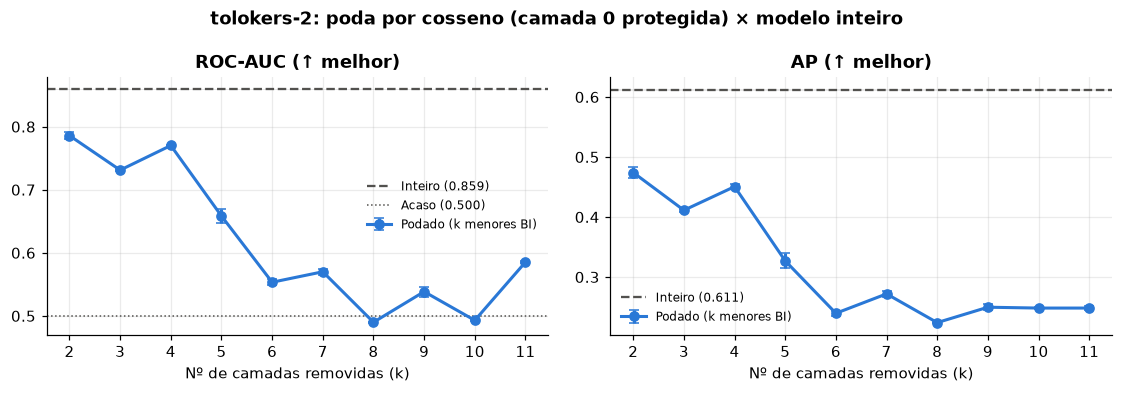

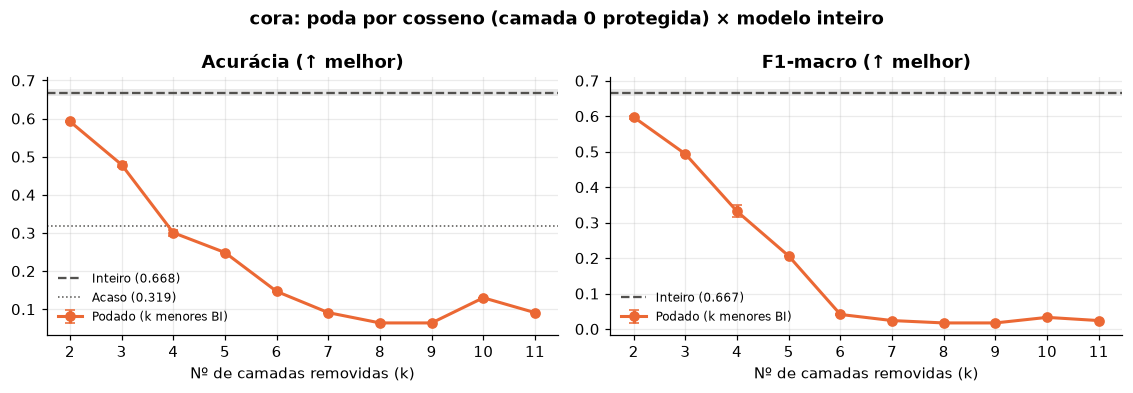

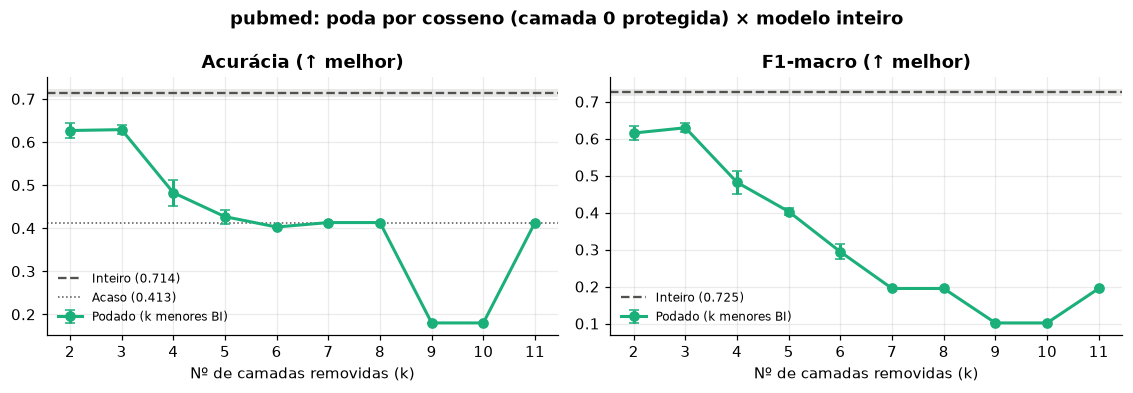

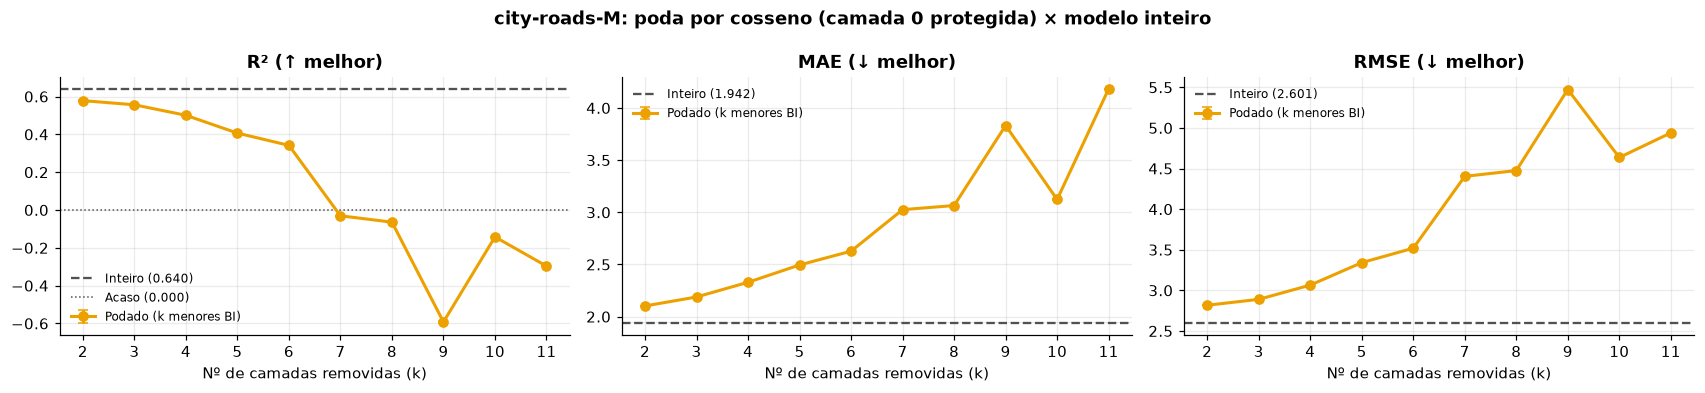

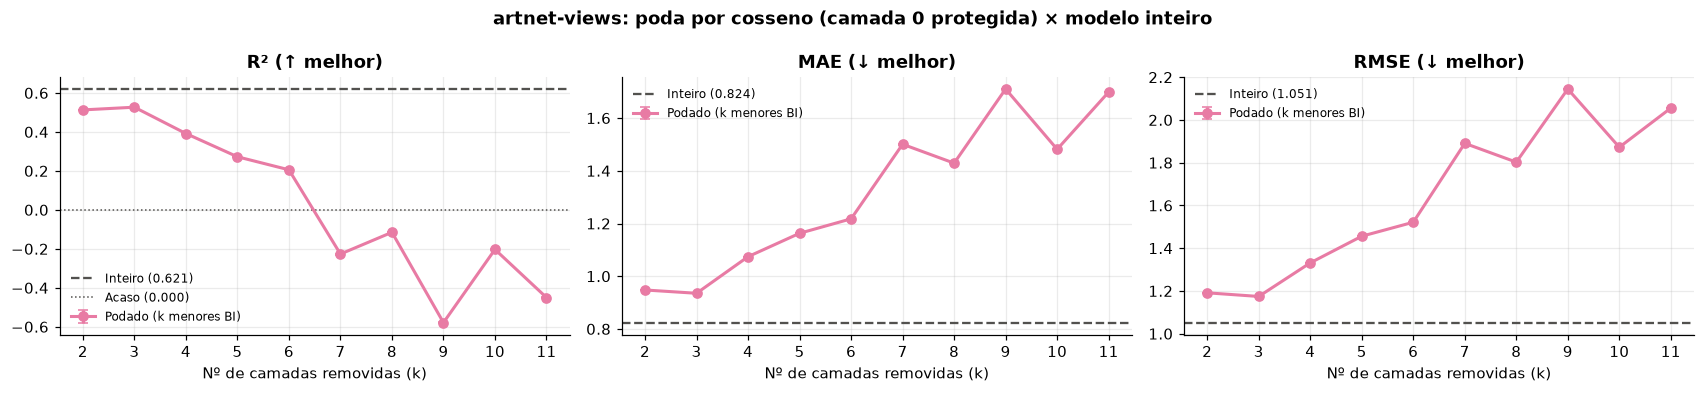

In [7]:
for j, name in enumerate(TASKS):
    t = TASKS[name]; d = df_raw[df_raw.dataset == name]
    ms = METRICS[t["task"]]
    fig, axes = plt.subplots(1, len(ms), figsize=(5.2 * len(ms), 3.6), squeeze=False)
    for ax, m in zip(axes[0], ms):
        g = d[d.k > 0].groupby("k")[f"test_{m}"]
        full = d[d.k == 0][f"test_{m}"]
        ax.axhspan(full.mean() - full.std(), full.mean() + full.std(), color=GRAY, alpha=0.12, lw=0)
        ax.axhline(full.mean(), color=GRAY, ls="--", lw=1.5, label=f"Inteiro ({full.mean():.3f})")
        if m == t["metric"]:
            ax.axhline(t["chance"], color=GRAY, ls=":", lw=1, label=f"Acaso ({t['chance']:.3f})")
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", color=COLORS[j], capsize=3,
                    label="Podado (k menores BI)")
        ax.set_xticks(K_LIST)
        ax.set_xlabel("Nº de camadas removidas (k)")
        ax.set_title(METRIC_LABEL[m] + (" (↓ melhor)" if m in LOWER_IS_BETTER else " (↑ melhor)"))
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{name}: poda por cosseno (camada 0 protegida) × modelo inteiro", fontweight="bold")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"metricas_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

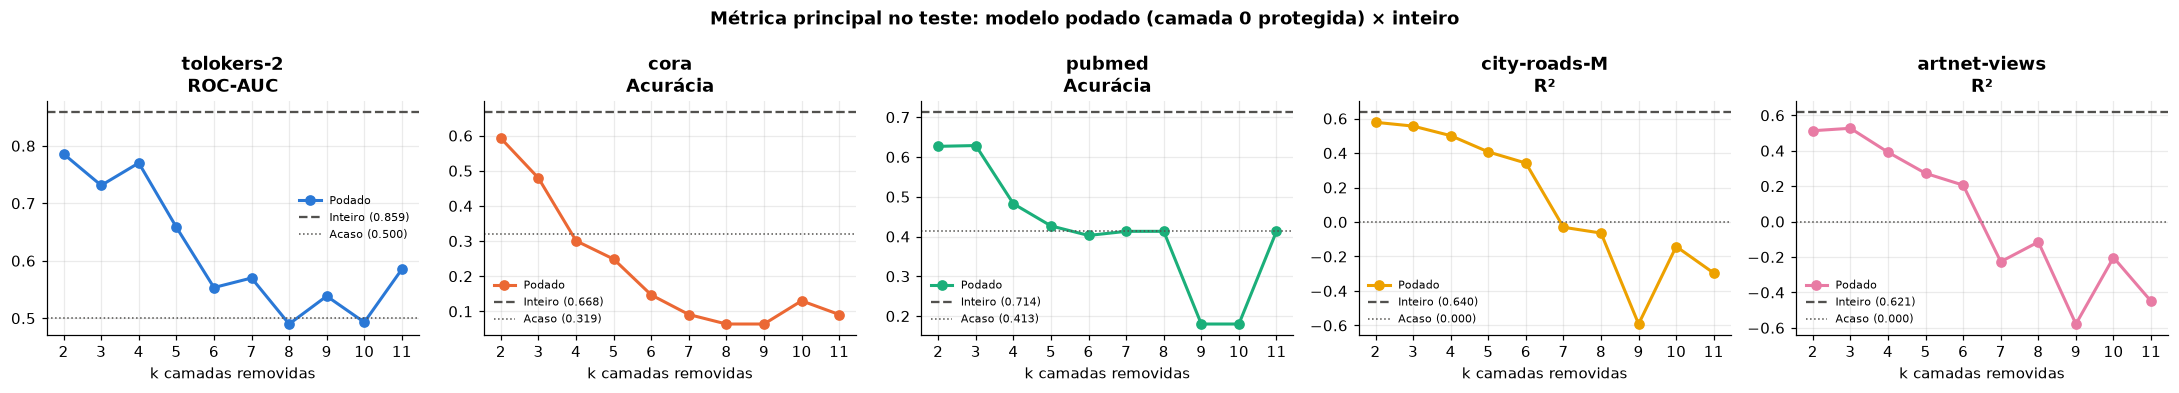

In [8]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3.6))
for j, (ax, name) in enumerate(zip(axes, TASKS)):
    t = TASKS[name]
    y = df_raw[df_raw.dataset == name].groupby("k")[f"test_{t['metric']}"].mean()
    ax.plot(y.index[1:], y.values[1:], marker="o", color=COLORS[j], label="Podado")
    ax.axhline(y.loc[0], color=GRAY, ls="--", lw=1.5, label=f"Inteiro ({y.loc[0]:.3f})")
    ax.axhline(t["chance"], color=GRAY, ls=":", lw=1, label=f"Acaso ({t['chance']:.3f})")
    ax.set_xticks(K_LIST)
    ax.set_xlabel("k camadas removidas")
    ax.set_title(f"{name}\n{METRIC_LABEL[t['metric']]}")
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Métrica principal no teste: modelo podado (camada 0 protegida) × inteiro", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "metrica_principal_todos.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.4 Comparação: camada 0 protegida × sem restrição

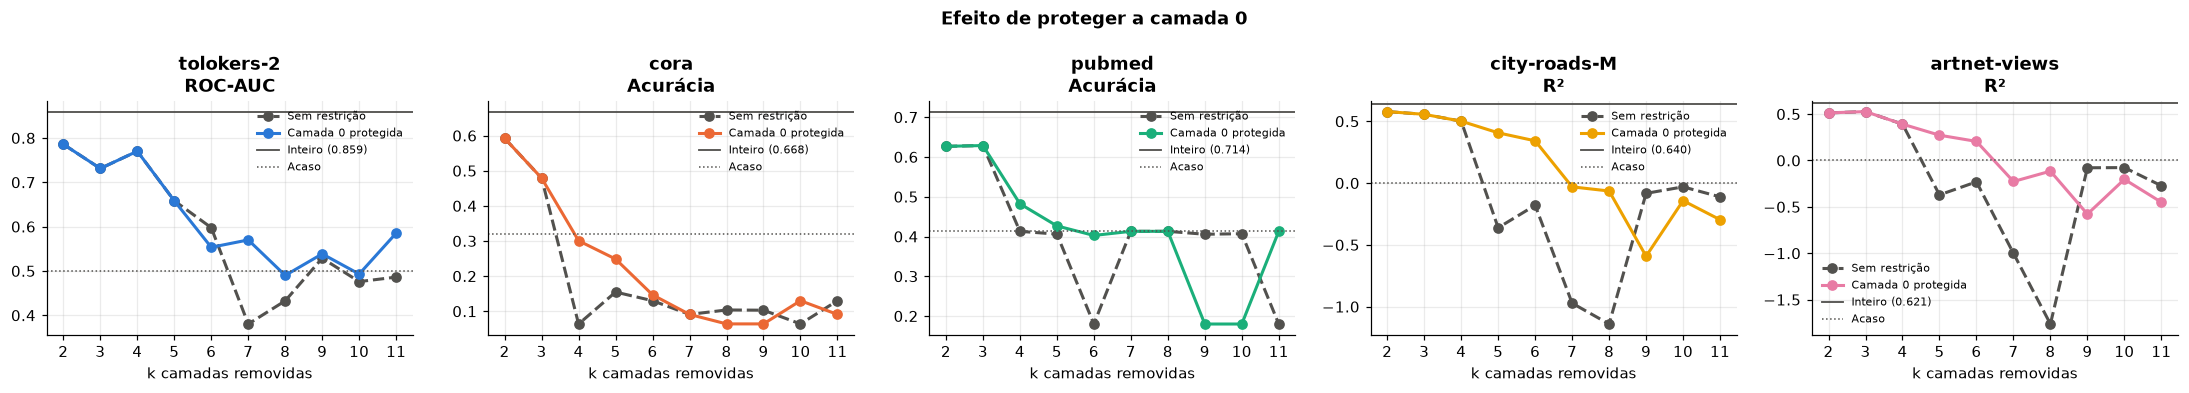

In [9]:
free_path = FREE_DIR / "poda_cosseno_k.csv"
if not free_path.exists():
    print(f"Execute antes poda_cosseno_k_menores_graphpfn.ipynb para gerar {free_path}")
else:
    df_free = pd.read_csv(free_path)
    rows = []
    for n in TASKS:
        m = f"test_{TASKS[n]['metric']}"
        prot = df_raw[df_raw.dataset == n].groupby("k")[m].mean()
        free = df_free[df_free.dataset == n].groupby("k")[m].mean()
        for k in prot.index:
            rows.append({"dataset": n, "k": k, "métrica": METRIC_LABEL[TASKS[n]["metric"]],
                         "sem restrição": free.get(k, np.nan), "camada 0 protegida": prot[k]})
    cmp = pd.DataFrame(rows)
    cmp["diferença (protegida − livre)"] = cmp["camada 0 protegida"] - cmp["sem restrição"]
    cmp.to_csv(RESULTS_DIR / "comparacao_livre_vs_protegida.csv", index=False)
    wide = cmp.pivot(index="k", columns="dataset", values=["sem restrição", "camada 0 protegida"])
    wide = wide.swaplevel(axis=1)[list(TASKS)]
    wide.index = ["Inteiro" if k == 0 else f"Poda {k} menores" for k in wide.index]
    display(wide.style.format("{:.4f}").set_caption("Métrica principal no teste: sem restrição × camada 0 protegida"))

    fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3.6))
    for j, (ax, n) in enumerate(zip(axes, TASKS)):
        d = cmp[(cmp.dataset == n) & (cmp.k > 0)]
        full = cmp[(cmp.dataset == n) & (cmp.k == 0)]["camada 0 protegida"].iloc[0]
        ax.plot(d.k, d["sem restrição"], marker="o", color=GRAY, ls="--", label="Sem restrição")
        ax.plot(d.k, d["camada 0 protegida"], marker="o", color=COLORS[j], label="Camada 0 protegida")
        ax.axhline(full, color=GRAY, lw=1.2, label=f"Inteiro ({full:.3f})")
        ax.axhline(TASKS[n]["chance"], color=GRAY, ls=":", lw=1, label="Acaso")
        ax.set_xticks(K_LIST)
        ax.set_xlabel("k camadas removidas")
        ax.set_title(f"{n}\n{METRIC_LABEL[TASKS[n]['metric']]}")
        ax.legend(frameon=False, fontsize=7)
    fig.suptitle("Efeito de proteger a camada 0", fontweight="bold")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "comparacao_livre_vs_protegida.png", dpi=200, bbox_inches="tight")
    plt.show()

## 4. Conclusões

Valores no teste, média de 3 sementes (CSVs e figuras em `Block_Influence_results/graphfpn_poda_cosseno_k_sem_camada0/`). Entre parênteses está o valor da versão **sem restrição**, quando ele é diferente.

| Configuração | tolokers-2 ROC-AUC | cora Acurácia | pubmed Acurácia | city-roads-M R² | artnet-views R² |
|---|---|---|---|---|---|
| **Inteiro** | **0,859** | **0,668** | **0,714** | **0,640** | **0,621** |
| Poda 2 menores | 0,786 | 0,592 | 0,627 | 0,578 | 0,513 |
| Poda 3 menores | 0,731 | 0,479 | 0,629 | 0,556 | 0,527 |
| Poda 4 menores | 0,770 | 0,301 (0,064) | 0,482 (0,413) | 0,501 | 0,392 |
| Poda 5 menores | 0,658 | 0,249 (0,155) | 0,427 (0,406) | 0,407 (−0,362) | 0,272 (−0,371) |
| Poda 6 menores | 0,553 (0,598) | 0,147 (0,130) | 0,403 (0,180) | 0,342 (−0,180) | 0,206 (−0,230) |
| Poda 7 menores | 0,570 (0,380) | 0,091 | 0,413 | −0,031 (−0,972) | −0,227 (−1,000) |
| Poda 8 a 11 menores | 0,49–0,59 | 0,06–0,13 | 0,18–0,41 | −0,59 a −0,06 | −0,58 a −0,12 |

1. **Até k = 3 nada muda.** A camada 0 só entrava na lista da versão livre a partir de k = 4 (cora/pubmed) ou k = 5 (regressão). Os resultados de k = 2 e 3 são idênticos nas duas versões, assim como os de tolokers-2 até k = 5.
2. **Proteger a camada 0 evita o colapso abrupto.** Na regressão, R² com k = 5 passa de −0,36 para 0,41 (city-roads-M) e de −0,37 para 0,27 (artnet-views). Com k = 6 ainda fica positivo (0,34 e 0,21). No cora com k = 4, a acurácia sobe de 0,064 para 0,301.
3. **Mas isso não torna a poda viável.** A degradação deixa de ser um degrau e vira uma queda contínua: cada camada removida custa mais desempenho. Nenhum k ≥ 2 chega perto do inteiro. Em classificação, com k ≥ 4 o modelo já fica perto do acaso (pubmed 0,40–0,48 contra acaso de 0,413; cora ≤ 0,30 contra acaso de 0,319).
4. **Para k ≥ 9 a versão protegida às vezes fica pior que a livre** (regressão, pubmed). Nesse ponto os dois modelos já estão abaixo do acaso, e a diferença é ruído entre modelos quebrados.
5. **A camada 1 é o próximo gargalo em classificação.** Ela é a primeira removida (menor BI em todos os datasets), e só com isso a acurácia já cai 7 a 9 pontos. Uma próxima versão pode proteger {0, 1} em classificação ou usar o BI do token-alvo (`BI_COL = "cos_tgt"`).

**Resumo:** proteger a camada 0 corrige a falha mais grave do BI na média de todos os tokens e faz a regressão sobreviver até k = 6 com R² positivo. Mesmo assim, sem re-treino, a poda por cosseno continua sem preservar o desempenho do modelo inteiro para nenhum k ≥ 2.
